In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Dataset load karein
df = pd.read_csv('diabetes_prediction_dataset.csv')
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [2]:
# Target column ('diabetes') hata dein kyunki K-Means unsupervised hai
X = df.drop('diabetes', axis=1)

# Categorical columns ('gender', 'smoking_history') ko numeric mein badlein
X_encoded = pd.get_dummies(X, columns=['gender', 'smoking_history'], drop_first=True)

# Data ko scale karein
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

print("Preprocessed Data Shape:", X_scaled.shape)

Preprocessed Data Shape: (100000, 13)


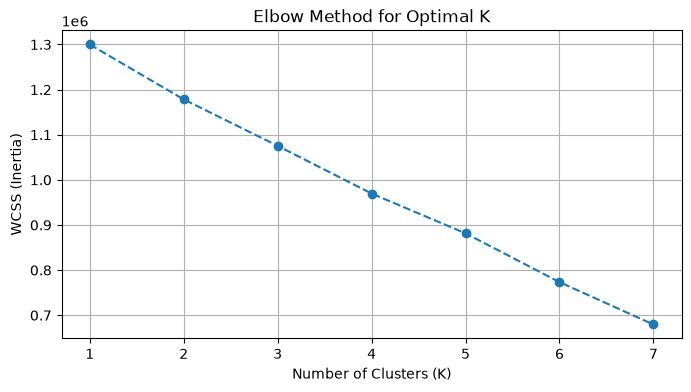

In [3]:
wcss = []
K_range = range(1, 8)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

In [4]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print("Har Cluster mein Patients ki Sankhya:")
print(df['Cluster'].value_counts())

Har Cluster mein Patients ki Sankhya:
Cluster
2    51036
1    31147
0    17817
Name: count, dtype: int64


In [5]:
cluster_summary = df.groupby('Cluster')[['age', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']].mean().round(2)
print(cluster_summary)

           age    bmi  HbA1c_level  blood_glucose_level  diabetes
Cluster                                                          
0        59.85  29.98         5.74               146.73      0.22
1        41.45  27.74         5.51               137.10      0.07
2        35.88  26.13         5.47               135.61      0.05


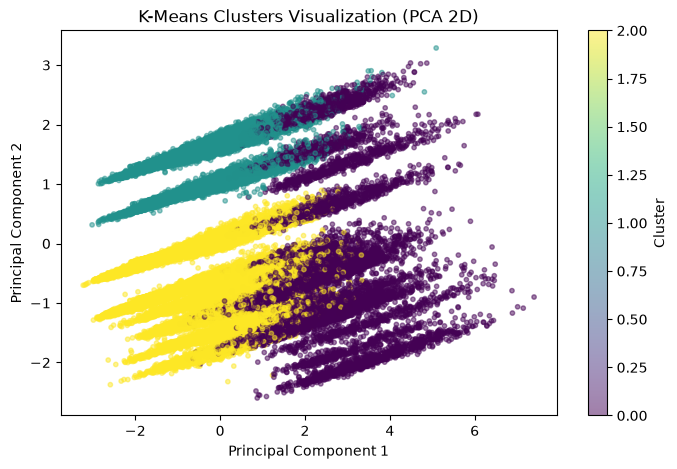

In [6]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['Cluster'], cmap='viridis', alpha=0.5, s=10)
plt.title('K-Means Clusters Visualization (PCA 2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(scatter, label='Cluster')
plt.show()

In [8]:
df.to_csv('diabetes_clustered_output.csv', index=False)
print("File successfully!")

File successfully!
